# Training FNO, MRBNO, and PCA Net on Nonlinear Diffusion Dataset

Train and compare three models:
1. **FNO** (Fourier Neural Operator) - layers=4, width=24, modes=(12,12)
2. **MRBNO Lift Simple** (Multi-layer Reduced Basis Neural Operator) - layers=4, width=24, n_modes=144
3. **PCA Net** (Simple neural network operating in PCA coefficient space) - depth=5, hidden=1024, k_in=144, k_out=144

on the nonlinear PDE: $-\nabla \cdot (e^{m(x)} \nabla u) = f$

**Note:** PCA Net and MRBNO Lift Simple use the same PCA reducer to ensure fair comparison.

**Training settings:**
- Cosine annealing LR schedule with lr=2e-3
- Gradient clipping: max_grad_norm=3.0
- Early stopping: patience=50
- Using 1000 samples (700 train, 200 val, 100 test)
- Loss: Relative L1


## 1. Load Dataset and Imports


In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import sys
import os

# Add models directory to path
sys.path.append('models')

from FNO_model import FNO2d
from MRBNO_lift_simple import MRBNOLiftSimple
from MRBNO_simple import PCAReducerMultiChannel
from PCANet import PCANet

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
data = np.load('/pscratch/sd/d/dvod/data/nonlinear_diffusion_dataset_rough.npz')


Loaded 20000 samples
Grid size: 100x100
Domain: [0, 1.0]^2

Input X shape: (20000, 2, 100, 100)
Output Y shape: (20000, 100, 100)


## 2. Normalize and Split Data


In [3]:
# Train/val/test split (70/20/10 like hyperparameter_sweep.py)
# Use actual length of loaded data, not num_samples
actual_samples = len(X)
train_frac = 0.7
val_frac = 0.2
n_train = int(train_frac * actual_samples)
n_val = int(val_frac * actual_samples)

X_train, Y_train = X[:n_train], Y[:n_train]
X_val, Y_val = X[n_train:n_train+n_val], Y[n_train:n_train+n_val]
X_test, Y_test = X[n_train+n_val:], Y[n_train+n_val:]

print(f"\nTraining samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"Test samples: {len(X_test)}")

# Normalize using train statistics only
x_mean = X_train.mean()
x_std = X_train.std()
y_mean = Y_train.mean()
y_std = Y_train.std()

X_train = (X_train - x_mean) / (x_std + 1e-8)
Y_train = (Y_train - y_mean) / (y_std + 1e-8)
X_val = (X_val - x_mean) / (x_std + 1e-8)
Y_val = (Y_val - y_mean) / (y_std + 1e-8)
X_test = (X_test - x_mean) / (x_std + 1e-8)
Y_test = (Y_test - y_mean) / (y_std + 1e-8)

print(f"X normalization: mean={x_mean:.4f}, std={x_std:.4f}")
print(f"Y normalization: mean={y_mean:.4f}, std={y_std:.4f}")
X_test_t = torch.from_numpy(X_test).float()
Y_test_t = torch.from_numpy(Y_test).float().unsqueeze(1) if not is_complex else torch.from_numpy(Y_test).float()
test_loader_fno = DataLoader(TensorDataset(X_test_t, Y_test_t), batch_size=32, shuffle=False)
test_loader_mrbno = DataLoader(TensorDataset(X_test_t, Y_test_t), batch_size=32, shuffle=False)
test_loader_pcanet = DataLoader(TensorDataset(X_test_t, Y_test_t), batch_size=32, shuffle=False)



Training samples: 14000
Validation samples: 4000
Test samples: 2000
X normalization: mean=-0.0049, std=1.7382
Y normalization: mean=-0.0007, std=0.0870


## 3. Prepare Data and PCA


In [ ]:
# Convert to PyTorch tensors
X_train_t = torch.from_numpy(X_train).float()
Y_train_t = torch.from_numpy(Y_train).float().unsqueeze(1)
X_val_t = torch.from_numpy(X_val).float()
Y_val_t = torch.from_numpy(Y_val).float().unsqueeze(1)
X_test_t = torch.from_numpy(X_test).float()
Y_test_t = torch.from_numpy(Y_test).float().unsqueeze(1)

print(f"Training data: X={X_train_t.shape}, Y={Y_train_t.shape}")
print(f"Validation data: X={X_val_t.shape}, Y={Y_val_t.shape}")
print(f"Test data: X={X_test_t.shape}, Y={Y_test_t.shape}")

# Create data loaders
batch_size = 32

train_loader_fno = DataLoader(TensorDataset(X_train_t, Y_train_t), batch_size=batch_size, shuffle=True)
val_loader_fno = DataLoader(TensorDataset(X_val_t, Y_val_t), batch_size=batch_size, shuffle=False)
test_loader_fno = DataLoader(TensorDataset(X_test_t, Y_test_t), batch_size=batch_size, shuffle=False)

train_loader_mrbno = DataLoader(TensorDataset(X_train_t, Y_train_t), batch_size=batch_size, shuffle=True)
val_loader_mrbno = DataLoader(TensorDataset(X_val_t, Y_val_t), batch_size=batch_size, shuffle=False)
test_loader_mrbno = DataLoader(TensorDataset(X_test_t, Y_test_t), batch_size=batch_size, shuffle=False)

train_loader_pcanet = DataLoader(TensorDataset(X_train_t, Y_train_t), batch_size=batch_size, shuffle=True)
val_loader_pcanet = DataLoader(TensorDataset(X_val_t, Y_val_t), batch_size=batch_size, shuffle=False)
test_loader_pcanet = DataLoader(TensorDataset(X_test_t, Y_test_t), batch_size=batch_size, shuffle=False)

print(f"Batch size: {batch_size}")

# Compute PCA ONCE - shared by both MRBNO Lift Simple and PCA Net
rb = PCAReducerMultiChannel(
    bc_weight=1.0, 
    boundary_threshold=0.1, 
    use_boundary_weighting=False,
).fit(X_train, Y_train)
k_in, k_out = 144, 144

print(f"\nPCA components (shared by MRBNO and PCA Net): k_in={k_in}, k_out={k_out} (fixed)")
print(f"Boundary condition awareness: bc_weight={rb.bc_weight}, threshold={rb.boundary_threshold}")
print(f"PCA whiten: {getattr(rb, 'whiten', False)}")


Training data: X=torch.Size([14000, 2, 100, 100]), Y=torch.Size([14000, 1, 100, 100])
Validation data: X=torch.Size([4000, 2, 100, 100]), Y=torch.Size([4000, 1, 100, 100])
Batch sizes: FNO=32, MRBNO=32, PCA Net=32

PCA components (shared by MRBNO and PCA Net): k_in=125, k_out=66
Boundary condition awareness: bc_weight=1.0, threshold=0.1
PCA whiten: False



PCA ANALYSIS AND SAMPLE VISUALIZATION


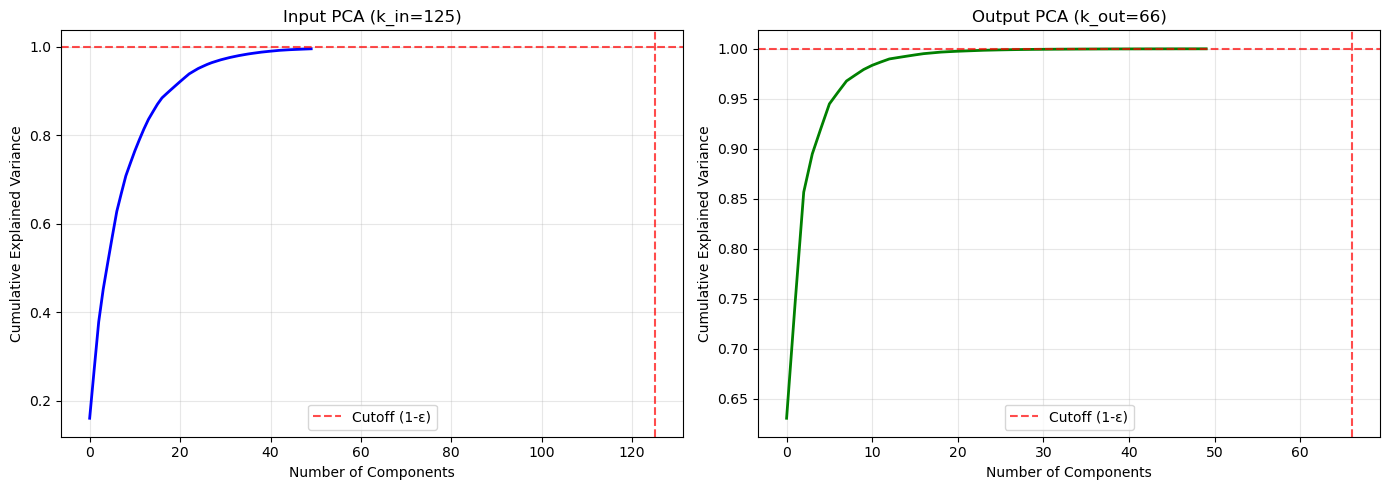

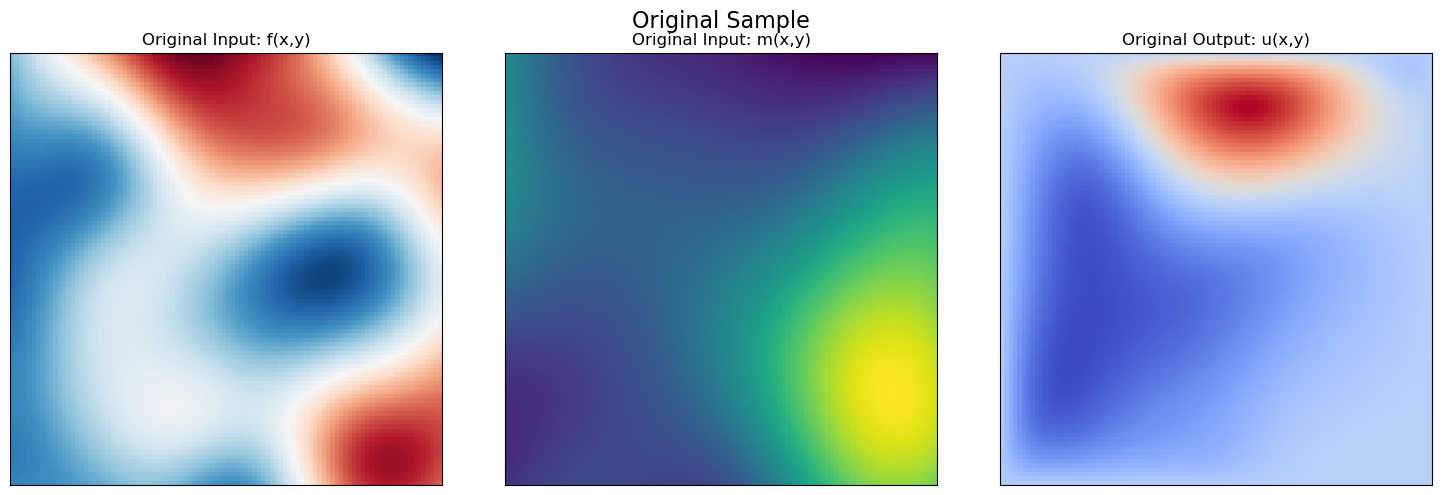

In [ ]:
# Visualize PCA components and sample reconstructions
print("\n" + "="*70)
print("PCA ANALYSIS AND SAMPLE VISUALIZATION")
print("="*70)

# Plot PCA explained variance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Input PCA variance
axes[0].plot(np.cumsum(rb.pca_in.explained_variance_ratio_[:50]), 'b-', linewidth=2)
axes[0].axhline(y=1-epsilon, color='r', linestyle='--', alpha=0.7, label=f'Cutoff (1-ε)')
axes[0].axvline(x=k_in, color='r', linestyle='--', alpha=0.7)
axes[0].set_xlabel('Number of Components')
axes[0].set_ylabel('Cumulative Explained Variance')
axes[0].set_title(f'Input PCA (k_in={k_in})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Output PCA variance
axes[1].plot(np.cumsum(rb.pca_out.explained_variance_ratio_[:50]), 'g-', linewidth=2)
axes[1].axhline(y=1-epsilon, color='r', linestyle='--', alpha=0.7, label=f'Cutoff (1-ε)')
axes[1].axvline(x=k_out, color='r', linestyle='--', alpha=0.7)
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title(f'Output PCA (k_out={k_out})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Visualize sample reconstructions with different ranks
sample_idx = 0
x_sample = X_train[sample_idx:sample_idx+1]  # (1, 2, 100, 100)
y_sample = Y_train[sample_idx:sample_idx+1]  # (1, 100, 100)

# Show original sample first
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(x_sample[0, 0], origin='lower', cmap='RdBu_r')
axes[0].set_title('Original Input: f(x,y)')
axes[0].set_xticks([])
axes[0].set_yticks([])

axes[1].imshow(x_sample[0, 1], origin='lower', cmap='viridis')
axes[1].set_title('Original Input: m(x,y)')
axes[1].set_xticks([])
axes[1].set_yticks([])

axes[2].imshow(y_sample[0], origin='lower', cmap='coolwarm')
axes[2].set_title('Original Output: u(x,y)')
axes[2].set_xticks([])
axes[2].set_yticks([])

plt.suptitle('Original Sample', fontsize=16)
plt.tight_layout()
plt.show()

# Reconstruct with different numbers of components
ranks_to_test = [5, 10, 20, 50, k_out]

fig, axes = plt.subplots(3, len(ranks_to_test), figsize=(20, 12))

for i, rank in enumerate(ranks_to_test):
    # Input reconstruction - need to use full multi-channel input
    x_flat = x_sample.reshape(1, -1)  # Flatten all channels: (1, 20000)
    x_coeffs = rb.pca_in.transform(x_flat)[:, :rank]
    x_reconstructed = rb.pca_in.inverse_transform(
        np.pad(x_coeffs, ((0, 0), (0, rb.pca_in.n_components_ - rank)), 'constant')
    ).reshape(1, 2, 100, 100)
    
    # Show both input channels
    axes[0, i].imshow(x_reconstructed[0, 0], origin='lower', cmap='RdBu_r')
    axes[0, i].set_title(f'Input f (rank {rank})')
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])
    
    axes[1, i].imshow(x_reconstructed[0, 1], origin='lower', cmap='viridis')
    axes[1, i].set_title(f'Input m (rank {rank})')
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])
    
    # Output reconstruction
    y_flat = y_sample.reshape(1, -1)  # (1, 10000)
    y_coeffs = rb.pca_out.transform(y_flat)[:, :rank]
    y_reconstructed = rb.pca_out.inverse_transform(
        np.pad(y_coeffs, ((0, 0), (0, rb.pca_out.n_components_ - rank)), 'constant')
    ).reshape(100, 100)
    
    axes[2, i].imshow(y_reconstructed, origin='lower', cmap='coolwarm')
    axes[2, i].set_title(f'Output u (rank {rank})')
    axes[2, i].set_xticks([])
    axes[2, i].set_yticks([])

plt.suptitle('Sample Reconstructions with Different PCA Ranks', fontsize=16)
plt.tight_layout()
plt.show()

# Show reconstruction errors
print(f"\nReconstruction errors for sample {sample_idx}:")
print("Rank\tInput MSE\tOutput MSE")
print("-" * 35)
for rank in ranks_to_test:
    # Input error - use full multi-channel input
    x_flat = x_sample.reshape(1, -1)
    x_coeffs = rb.pca_in.transform(x_flat)[:, :rank]
    x_reconstructed = rb.pca_in.inverse_transform(
        np.pad(x_coeffs, ((0, 0), (0, rb.pca_in.n_components_ - rank)), 'constant')
    ).reshape(1, 2, 100, 100)
    x_mse = np.mean((x_reconstructed - x_sample)**2)
    
    # Output error
    y_flat = y_sample.reshape(1, -1)
    y_coeffs = rb.pca_out.transform(y_flat)[:, :rank]
    y_reconstructed = rb.pca_out.inverse_transform(
        np.pad(y_coeffs, ((0, 0), (0, rb.pca_out.n_components_ - rank)), 'constant')
    ).reshape(100, 100)
    y_mse = np.mean((y_reconstructed - y_sample[0])**2)
    
    print(f"{rank}\t{x_mse:.2e}\t{y_mse:.2e}")


## 4. Training Function


In [ ]:
def relative_l1_loss(pred, target):
    """Compute relative L1 loss: ||pred - target||_1 / ||target||_1"""
    if pred.ndim == 4 and pred.shape[1] == 1:
        pred = pred.squeeze(1)
    if target.ndim == 4 and target.shape[1] == 1:
        target = target.squeeze(1)
    error = torch.abs(pred - target)
    return torch.mean(error / (torch.abs(target) + 1e-10))

def train_model(model, train_loader, val_loader, epochs=300, lr=2e-3, weight_decay=1e-4, max_grad_norm=3.0, 
                device='cpu', early_stopping_patience=50, early_stopping_min_delta=0.0):
    """Train model with cosine annealing LR schedule and early stopping."""
    import time
    start_time = time.time()
    
    model.to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
        betas=(0.9, 0.999),
        eps=1e-8
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=0.0)
    criterion = relative_l1_loss
    
    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    best_epoch = 0
    patience_counter = 0
    
    # Check if validation set is empty
    has_val = len(val_loader.dataset) > 0
    
    for epoch in range(epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_loader.dataset)
        
        # Validation phase
        if has_val:
            model.eval()
            val_loss = 0.0
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(device), yb.to(device)
                    pred = model(xb)
                    loss = criterion(pred, yb)
                    val_loss += loss.item() * xb.size(0)
            val_loss /= len(val_loader.dataset)
        else:
            val_loss = float('inf')  # No validation data
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        
        # Early stopping logic
        improved = False
        if has_val:
            if val_loss < best_val_loss - early_stopping_min_delta:
                best_val_loss = val_loss
                best_epoch = epoch
                patience_counter = 0
                improved = True
            else:
                patience_counter += 1
        else:
            # If no validation, use training loss
            if train_loss < best_val_loss - early_stopping_min_delta:
                best_val_loss = train_loss
                best_epoch = epoch
                patience_counter = 0
                improved = True
            else:
                patience_counter += 1
        
        scheduler.step()
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            if has_val:
                print(f"[{epoch+1:03d}/{epochs}] train={train_loss:.4e} val={val_loss:.4e} lr={scheduler.get_last_lr()[0]:.2e} (best: {best_val_loss:.4e} @ epoch {best_epoch+1})")
            else:
                print(f"[{epoch+1:03d}/{epochs}] train={train_loss:.4e} (no val) lr={scheduler.get_last_lr()[0]:.2e} (best: {best_val_loss:.4e} @ epoch {best_epoch+1})")
        
        # Early stopping
        if patience_counter >= early_stopping_patience:
            print(f"Early stopping triggered at epoch {epoch+1} (patience={early_stopping_patience})")
            break
    
    training_time = time.time() - start_time
    
    return train_losses, val_losses, best_val_loss, training_time, best_epoch + 1


## 5. Train All Three Models


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else 
                      "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

# Checkpoint configuration - set to True to load existing checkpoints (skip training)
# Set to False to train from scratch
use_checkpoint_fno = False
use_checkpoint_mrbno = False
use_checkpoint_pcanet = False

checkpoint_dir = 'checkpoints'
os.makedirs(checkpoint_dir, exist_ok=True)


## 5a. Train FNO Model


In [8]:
# Train or load FNO model
print("\n" + "="*70)
print("FNO MODEL")
print("="*70)
fno_model = FNO2d(in_channels=2, out_channels=1, width=24, modes=(12, 12), n_layers=4)
print(f"FNO Parameters: {sum(p.numel() for p in fno_model.parameters()):,}")

fno_checkpoint_path = os.path.join(checkpoint_dir, 'fno_nonlinear_best.pt')

if use_checkpoint_fno and os.path.exists(fno_checkpoint_path):
    print(f"Loading FNO checkpoint from {fno_checkpoint_path}...")
    fno_model.load_state_dict(torch.load(fno_checkpoint_path, map_location=device))
    fno_model.to(device)
    fno_model.eval()
    print("FNO checkpoint loaded. Skipping training.")
    # Evaluate to get validation loss
    criterion = nn.MSELoss()
    val_loss = 0.0
    with torch.no_grad():
        for xb, yb in val_loader_fno:
            xb, yb = xb.to(device), yb.to(device)
            pred = fno_model(xb)
            loss = criterion(pred, yb)
            val_loss += loss.item() * xb.size(0)
    fno_best_val = val_loss / len(val_loader_fno.dataset)
    fno_train_losses, fno_val_losses = [], []  # Not available from checkpoint
    fno_training_time = 0.0
    fno_best_epoch = 0
    print(f"FNO validation loss: {fno_best_val:.4e}")
else:
    print("Training FNO from scratch...")
    fno_train_losses, fno_val_losses, fno_best_val, fno_training_time, fno_best_epoch = train_model(
        fno_model, train_loader_fno, val_loader_fno, epochs=300, lr=2e-3, max_grad_norm=3.0, 
        device=device, early_stopping_patience=50
    )
    torch.save(fno_model.state_dict(), fno_checkpoint_path)
    print(f"FNO model saved to {fno_checkpoint_path}")
    print(f"Training time: {fno_training_time:.2f} seconds ({fno_training_time/60:.2f} minutes)")


[010/300] train=2.1894e-02 val=1.7759e-02 lr=1.99e-03 (best: 1.7759e-02 @ epoch 10)
[020/300] train=7.9164e-03 val=1.0784e-02 lr=1.98e-03 (best: 1.0784e-02 @ epoch 20)
[030/300] train=6.1445e-03 val=1.0798e-02 lr=1.95e-03 (best: 1.0106e-02 @ epoch 28)
[040/300] train=6.6889e-03 val=8.6649e-03 lr=1.91e-03 (best: 8.6649e-03 @ epoch 40)
[050/300] train=4.2996e-03 val=8.0891e-03 lr=1.87e-03 (best: 7.4646e-03 @ epoch 46)
[060/300] train=3.2500e-03 val=9.6534e-03 lr=1.81e-03 (best: 6.8408e-03 @ epoch 59)
[070/300] train=2.5929e-03 val=6.2627e-03 lr=1.74e-03 (best: 6.1074e-03 @ epoch 65)
[080/300] train=2.7063e-03 val=6.5927e-03 lr=1.67e-03 (best: 6.1074e-03 @ epoch 65)
[090/300] train=1.8403e-03 val=5.9135e-03 lr=1.59e-03 (best: 5.8277e-03 @ epoch 89)
[100/300] train=2.0176e-03 val=5.9305e-03 lr=1.50e-03 (best: 5.5831e-03 @ epoch 94)
[110/300] train=1.5523e-03 val=5.4761e-03 lr=1.41e-03 (best: 5.4761e-03 @ epoch 110)
[120/300] train=1.7888e-03 val=5.3887e-03 lr=1.31e-03 (best: 5.2940e-03 @ e

## 5b. Train MRBNO Lift Simple Model


In [ ]:
mrbno_model = MRBNOLiftSimple(
    in_channels=2,
    out_channels=1,
    width=24,
    n_modes=144,
    n_layers=4,
    add_coords=True,
    norm="group",
    dropout_p=0.0,
    residual=True,
    pca_components=rb.pca_out.components_,
    pca_mean=rb.pca_out.mean_
)



MRBNO LIFT V3 MODEL
MRBNO Lift v3 Parameters: 21,283,634
Training MRBNO from scratch...
Using reduced batch size 32 to avoid OOM
[001/300] train=4.3637e-01 val=1.2620e-01 lr=2.00e-03 (best: 1.2620e-01 @ epoch 1)
[010/300] train=2.9208e-02 val=2.9964e-02 lr=1.99e-03 (best: 2.9964e-02 @ epoch 10)
[020/300] train=1.8332e-02 val=1.8871e-02 lr=1.98e-03 (best: 1.8871e-02 @ epoch 20)
[030/300] train=1.2728e-02 val=1.3397e-02 lr=1.95e-03 (best: 1.3397e-02 @ epoch 30)
[040/300] train=1.2792e-02 val=1.3550e-02 lr=1.91e-03 (best: 1.1117e-02 @ epoch 38)
[050/300] train=1.2715e-02 val=1.6657e-02 lr=1.87e-03 (best: 9.2522e-03 @ epoch 48)
[060/300] train=1.0794e-02 val=1.2649e-02 lr=1.81e-03 (best: 9.0037e-03 @ epoch 55)
[070/300] train=8.9461e-03 val=1.0157e-02 lr=1.74e-03 (best: 8.8161e-03 @ epoch 62)
[080/300] train=6.1280e-03 val=7.8326e-03 lr=1.67e-03 (best: 7.5682e-03 @ epoch 76)
[090/300] train=6.9305e-03 val=7.5639e-03 lr=1.59e-03 (best: 6.9485e-03 @ epoch 89)
[100/300] train=5.0433e-03 val=

In [10]:
## 5c. Train PCA Net Model


In [ ]:
pcanet_model = PCANet(
    rb=rb,
    k_in=144,
    k_out=144,
    hidden=1024,
    depth=5,
    dropout=0.0,
    init_scale=0.1,
)



TRAINING PCA NET
PCA Net Parameters: 4,395,074
[001/300] train=5.2694e-01 val=4.2327e-01 lr=2.00e-03 (best: 4.2327e-01 @ epoch 1)
[010/300] train=1.9231e-01 val=1.9757e-01 lr=1.99e-03 (best: 1.9757e-01 @ epoch 10)
[020/300] train=1.3168e-01 val=1.7542e-01 lr=1.98e-03 (best: 1.6006e-01 @ epoch 19)
[030/300] train=1.0366e-01 val=1.3698e-01 lr=1.95e-03 (best: 1.3698e-01 @ epoch 30)
[040/300] train=9.3111e-02 val=1.3233e-01 lr=1.91e-03 (best: 1.2760e-01 @ epoch 37)
[050/300] train=8.0454e-02 val=1.3082e-01 lr=1.87e-03 (best: 1.2507e-01 @ epoch 47)
[060/300] train=7.0337e-02 val=1.1999e-01 lr=1.81e-03 (best: 1.1999e-01 @ epoch 60)
[070/300] train=6.3748e-02 val=1.1860e-01 lr=1.74e-03 (best: 1.1860e-01 @ epoch 70)
[080/300] train=5.9893e-02 val=1.1440e-01 lr=1.67e-03 (best: 1.1440e-01 @ epoch 80)
[090/300] train=5.4969e-02 val=1.2034e-01 lr=1.59e-03 (best: 1.1311e-01 @ epoch 86)
[100/300] train=5.0558e-02 val=1.1104e-01 lr=1.50e-03 (best: 1.1104e-01 @ epoch 100)
[110/300] train=4.7356e-02 v

## 6. Training Results and Comparison


In [ ]:
# Compute train/val/test errors for all models
print("\n" + "="*70)
print("TRAINING COMPLETE - ERROR SUMMARY")
print("="*70)

def compute_rel_errors(model, loader, device, y_mean, y_std, is_complex=False):
    """Compute relative L1 and L2 errors"""
    model.eval()
    rel_l1_errors = []
    rel_l2_errors = []
    
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            
            pred_denorm = pred * y_std + y_mean
            yb_denorm = yb * y_std + y_mean
            
            for i in range(pred_denorm.size(0)):
                if is_complex:
                    pred_mag = torch.sqrt(pred_denorm[i, 0]**2 + pred_denorm[i, 1]**2 + 1e-10).cpu().numpy()
                    true_mag = torch.sqrt(yb_denorm[i, 0]**2 + yb_denorm[i, 1]**2 + 1e-10).cpu().numpy()
                else:
                    pred_mag = pred_denorm[i, 0].cpu().numpy() if pred_denorm.ndim == 4 else pred_denorm[i].cpu().numpy()
                    true_mag = yb_denorm[i, 0].cpu().numpy() if yb_denorm.ndim == 4 else yb_denorm[i].cpu().numpy()
                
                l1_err = np.abs(pred_mag - true_mag).sum()
                l1_norm = np.abs(true_mag).sum()
                rel_l1 = l1_err / (l1_norm + 1e-10)
                rel_l1_errors.append(rel_l1)
                
                l2_err = np.sqrt(np.sum((pred_mag - true_mag)**2))
                l2_norm = np.sqrt(np.sum(true_mag**2))
                rel_l2 = l2_err / (l2_norm + 1e-10)
                rel_l2_errors.append(rel_l2)
    
    return np.mean(rel_l1_errors) * 100, np.mean(rel_l2_errors) * 100

# Compute errors for all models
fno_train_l1, fno_train_l2 = compute_rel_errors(fno_model, train_loader_fno, device, y_mean, y_std, False)
fno_val_l1, fno_val_l2 = compute_rel_errors(fno_model, val_loader_fno, device, y_mean, y_std, False)
fno_test_l1, fno_test_l2 = compute_rel_errors(fno_model, test_loader_fno, device, y_mean, y_std, False)

mrbno_train_l1, mrbno_train_l2 = compute_rel_errors(mrbno_model, train_loader_mrbno, device, y_mean, y_std, False)
mrbno_val_l1, mrbno_val_l2 = compute_rel_errors(mrbno_model, val_loader_mrbno, device, y_mean, y_std, False)
mrbno_test_l1, mrbno_test_l2 = compute_rel_errors(mrbno_model, test_loader_mrbno, device, y_mean, y_std, False)

pcanet_train_l1, pcanet_train_l2 = compute_rel_errors(pcanet_model, train_loader_pcanet, device, y_mean, y_std, False)
pcanet_val_l1, pcanet_val_l2 = compute_rel_errors(pcanet_model, val_loader_pcanet, device, y_mean, y_std, False)
pcanet_test_l1, pcanet_test_l2 = compute_rel_errors(pcanet_model, test_loader_pcanet, device, y_mean, y_std, False)

print(f"\n{'Model':<20} {'Train Rel L1 (%)':<18} {'Train Rel L2 (%)':<18} {'Val Rel L1 (%)':<18} {'Val Rel L2 (%)':<18} {'Test Rel L1 (%)':<18} {'Test Rel L2 (%)':<18}")
print("-" * 130)
print(f"{'FNO':<20} {fno_train_l1:>16.4f}  {fno_train_l2:>16.4f}  {fno_val_l1:>16.4f}  {fno_val_l2:>16.4f}  {fno_test_l1:>16.4f}  {fno_test_l2:>16.4f}")
print(f"{'MRBNO Lift Simple':<20} {mrbno_train_l1:>16.4f}  {mrbno_train_l2:>16.4f}  {mrbno_val_l1:>16.4f}  {mrbno_val_l2:>16.4f}  {mrbno_test_l1:>16.4f}  {mrbno_test_l2:>16.4f}")
print(f"{'PCA Net':<20} {pcanet_train_l1:>16.4f}  {pcanet_train_l2:>16.4f}  {pcanet_val_l1:>16.4f}  {pcanet_val_l2:>16.4f}  {pcanet_test_l1:>16.4f}  {pcanet_test_l2:>16.4f}")

# Legacy function kept for compatibility
def compute_rel_l1_error_stats(model, val_loader, device, y_mean, y_std):
    """
    Compute relative L1 error statistics:
    - Mean relative L1 error: ||u_pred - u_true||_1 / ||u_true||_1
    - Standard deviation across samples
    - Average spatial gradient magnitude of relative error (measures spatial smoothness)
    - Per-sample errors (returned for analysis)
    """
    model.eval()
    per_sample_errors = []
    spatial_grad_magnitudes = []
    
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            
            # Denormalize
            pred_denorm = pred * y_std + y_mean
            yb_denorm = yb * y_std + y_mean
            
            batch_size = pred_denorm.size(0)
            
            # Compute per-sample relative L1 errors
            for i in range(batch_size):
                pred_sample = pred_denorm[i].cpu().numpy()  # (1, H, W) or (H, W)
                true_sample = yb_denorm[i].cpu().numpy()
                
                # Handle different shapes
                if pred_sample.ndim == 3:
                    pred_sample = pred_sample[0]
                    true_sample = true_sample[0]
                
                # Relative L1 error per sample
                l1_error = np.abs(pred_sample - true_sample).sum()
                l1_norm_true = np.abs(true_sample).sum()
                rel_l1 = l1_error / (l1_norm_true + 1e-10)
                per_sample_errors.append(rel_l1)
                
                # Spatial gradient magnitude of relative error (measures spatial smoothness)
                # Higher values = more spatial variation (jagged/noisy errors)
                # Lower values = smoother errors (spatially correlated)
                error_map = np.abs(pred_sample - true_sample)
                true_abs = np.abs(true_sample)
                rel_error_map = error_map / (true_abs + 1e-10)  # Relative error at each pixel
                
                # Compute spatial gradient
                grad_x, grad_y = np.gradient(rel_error_map)
                grad_magnitude = np.sqrt(grad_x**2 + grad_y**2)
                mean_grad_magnitude = np.mean(grad_magnitude)
                spatial_grad_magnitudes.append(mean_grad_magnitude)
    
    per_sample_errors = np.array(per_sample_errors)
    spatial_grad_magnitudes = np.array(spatial_grad_magnitudes)
    
    return {
        'mean': np.mean(per_sample_errors),
        'std': np.std(per_sample_errors),
        'spatial_grad_mean': np.mean(spatial_grad_magnitudes),
        'spatial_grad_std': np.std(spatial_grad_magnitudes),
        'per_sample_errors': per_sample_errors,
        'spatial_grad_magnitudes': spatial_grad_magnitudes
    }

# Compute enhanced error statistics (use appropriate loaders)
fno_stats = compute_rel_l1_error_stats(fno_model, val_loader_fno, device, y_mean, y_std)
mrbno_stats = compute_rel_l1_error_stats(mrbno_model, val_loader_mrbno, device, y_mean, y_std)
pcanet_stats = compute_rel_l1_error_stats(pcanet_model, val_loader_pcanet, device, y_mean, y_std)

fno_rel_l1 = fno_stats['mean']
mrbno_rel_l1 = mrbno_stats['mean']
pcanet_rel_l1 = pcanet_stats['mean']

# Measure inference time
import time
def measure_inference_time(model, val_loader, device, n_runs=10):
    """Measure average inference time per batch"""
    model.eval()
    times = []
    
    with torch.no_grad():
        for _ in range(n_runs):
            for xb, yb in val_loader:
                xb = xb.to(device)
                torch.cuda.synchronize() if device.type == 'cuda' else None
                start = time.time()
                _ = model(xb)
                torch.cuda.synchronize() if device.type == 'cuda' else None
                times.append(time.time() - start)
                break  # Only measure first batch
    return np.mean(times)

fno_inference_time = measure_inference_time(fno_model, val_loader_fno, device)
mrbno_inference_time = measure_inference_time(mrbno_model, val_loader_mrbno, device)
pcanet_inference_time = measure_inference_time(pcanet_model, val_loader_pcanet, device)

models_summary = [
    ("FNO", fno_train_losses, fno_val_losses, fno_best_val, fno_params, 
     fno_training_time, fno_inference_time, fno_rel_l1, fno_best_epoch),
    ("MRBNO Lift Simple", mrbno_train_losses, mrbno_val_losses, mrbno_best_val, 
     mrbno_params, mrbno_training_time, mrbno_inference_time, 
     mrbno_rel_l1, mrbno_best_epoch),
    ("PCA Net", pcanet_train_losses, pcanet_val_losses, pcanet_best_val, pcanet_params,
     pcanet_training_time, pcanet_inference_time, pcanet_rel_l1, pcanet_best_epoch),
]

print(f"\n{'Model':<20} {'Params':<12} {'Best Val Loss':<15} {'Rel L1 Error (mean±std)':<25} {'Spatial Grad Mag (mean±std)':<30} {'Train Time (min)':<18} {'Inf Time (ms)':<15} {'Best Epoch':<12}")
print("-" * 155)

# Print summary with new statistics
stats_list = [fno_stats, mrbno_stats, pcanet_stats]
for i, (model_name, train_losses, val_losses, best_val, params, train_time, inf_time, rel_l1, best_epoch) in enumerate(models_summary):
    stats = stats_list[i]
    rel_l1_str = f"{stats['mean']*100:.2f}% ± {stats['std']*100:.2f}%"
    spatial_grad_str = f"{stats['spatial_grad_mean']:.4e} ± {stats['spatial_grad_std']:.4e}"
    print(f"{model_name:<20} {params:>10,}  {best_val:>12.4e}  {rel_l1_str:<25}  {spatial_grad_str:<30}  {train_time/60:>16.2f}  {inf_time*1000:>13.2f}  {best_epoch:>10}")

print("\n" + "="*70)
print("DETAILED ERROR STATISTICS")
print("="*70)
print(f"\nFNO:")
print(f"  Relative L1 Error: {fno_stats['mean']*100:.4f}% ± {fno_stats['std']*100:.4f}%")
print(f"  Mean Spatial Gradient Magnitude: {fno_stats['spatial_grad_mean']:.6e} ± {fno_stats['spatial_grad_std']:.6e}")
print(f"    (Higher = more spatial variation/jagged errors, Lower = smoother errors)")
print(f"\nMRBNO Lift Simple:")
print(f"  Relative L1 Error: {mrbno_stats['mean']*100:.4f}% ± {mrbno_stats['std']*100:.4f}%")
print(f"  Mean Spatial Gradient Magnitude: {mrbno_stats['spatial_grad_mean']:.6e} ± {mrbno_stats['spatial_grad_std']:.6e}")
print(f"    (Higher = more spatial variation/jagged errors, Lower = smoother errors)")
print(f"\nPCA Net:")
print(f"  Relative L1 Error: {pcanet_stats['mean']*100:.4f}% ± {pcanet_stats['std']*100:.4f}%")
print(f"  Mean Spatial Gradient Magnitude: {pcanet_stats['spatial_grad_mean']:.6e} ± {pcanet_stats['spatial_grad_std']:.6e}")
print(f"    (Higher = more spatial variation/jagged errors, Lower = smoother errors)")



TRAINING COMPLETE - SUMMARY

Model                Params       Best Val Loss   Rel L1 Error (mean±std)   Spatial Grad Mag (mean±std)    Train Time (min)   Inf Time (ms)   Best Epoch  
-----------------------------------------------------------------------------------------------------------------------------------------------------------
FNO                     335,065    3.8718e-03  5.24% ± 2.97%              2.2892e+00 ± 3.3759e+01                    70.80           3.76         291
MRBNO Lift v3        21,283,634    3.7244e-03  4.56% ± 2.58%              1.7810e+00 ± 2.5978e+01                    61.43           3.85         250
PCA Net               4,395,074    1.0858e-01  42.39% ± 22.49%            1.2878e+01 ± 3.1032e+02                     5.39           0.44         142

DETAILED ERROR STATISTICS

FNO:
  Relative L1 Error: 5.2415% ± 2.9673%
  Mean Spatial Gradient Magnitude: 2.289236e+00 ± 3.375928e+01
    (Higher = more spatial variation/jagged errors, Lower = smoother error

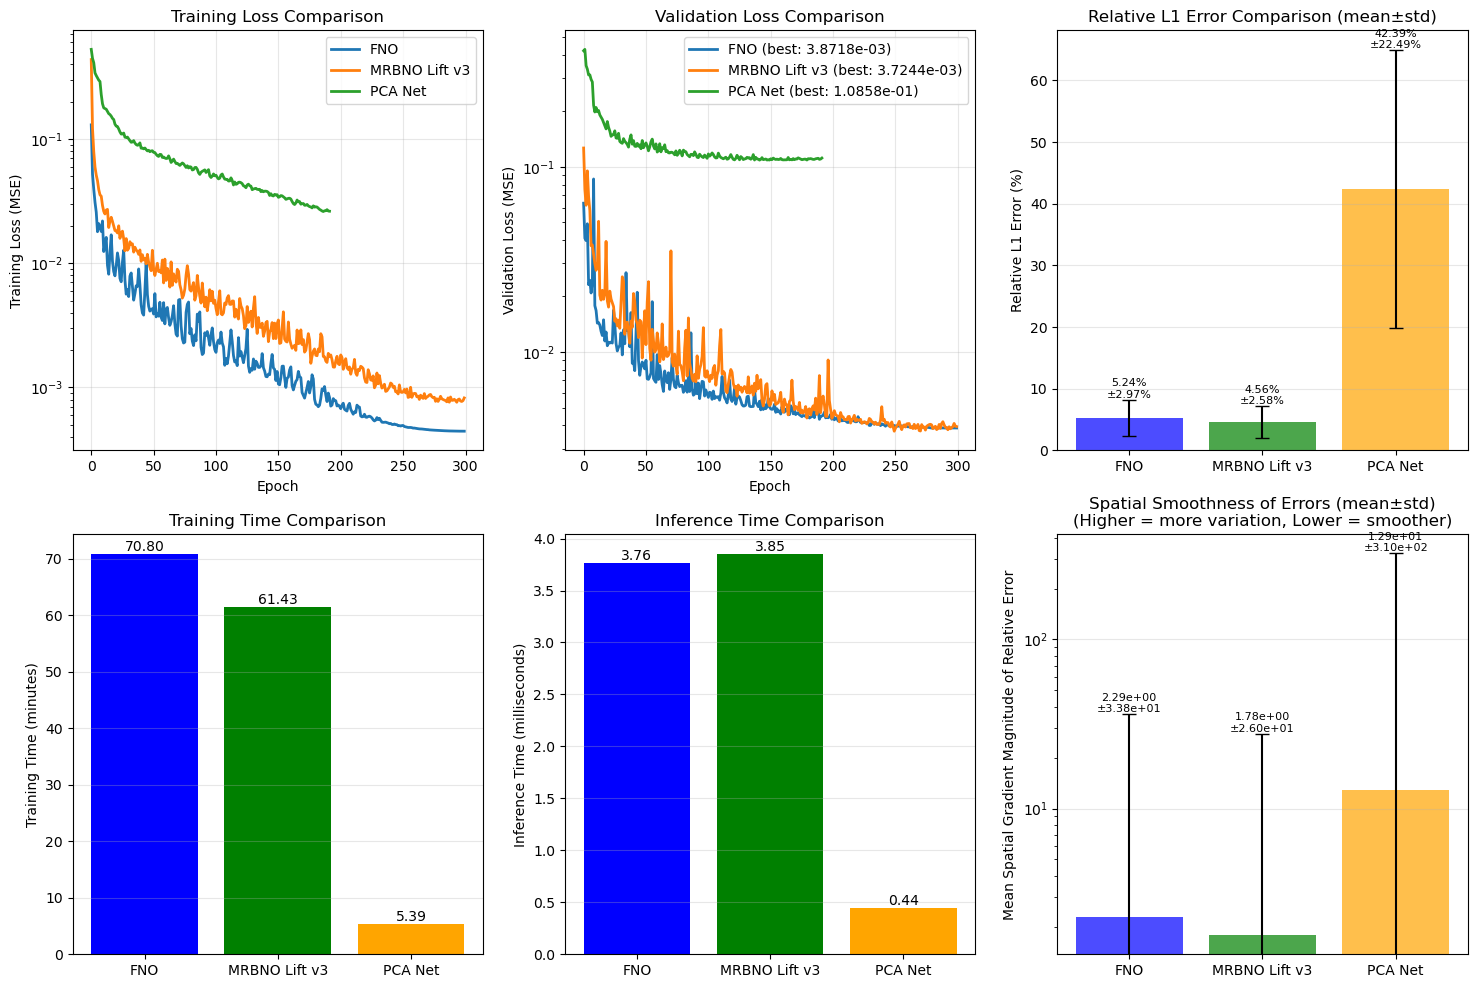

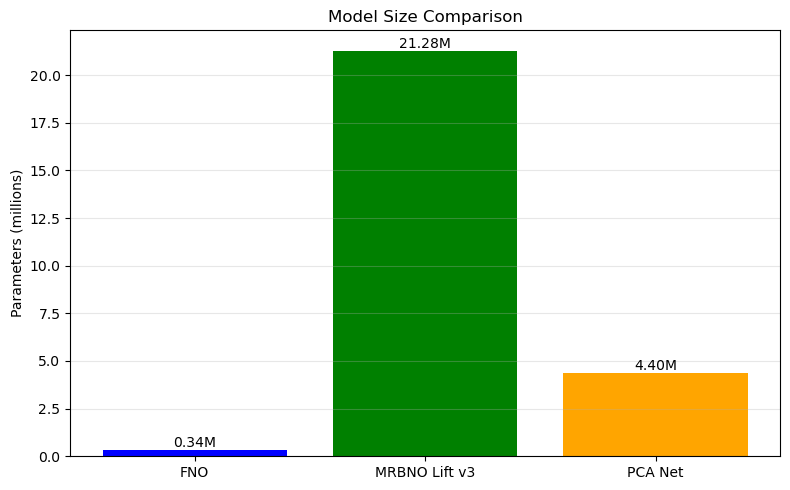

<Figure size 640x480 with 0 Axes>

In [15]:
# Comprehensive Training Curves Comparison with Relative L1 Errors
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Training Loss (only plot if available - skip if loaded from checkpoint)
if len(fno_train_losses) > 0:
    axes[0, 0].plot(fno_train_losses, label='FNO', linewidth=2)
if len(mrbno_train_losses) > 0:
    axes[0, 0].plot(mrbno_train_losses, label='MRBNO Lift Simple', linewidth=2)
if len(pcanet_train_losses) > 0:
    axes[0, 0].plot(pcanet_train_losses, label='PCA Net', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Training Loss (MSE)')
axes[0, 0].set_title('Training Loss Comparison' + (' (from checkpoints - no training curves)' if len(fno_train_losses) == 0 else ''))
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
if len(fno_train_losses) > 0 or len(mrbno_train_losses) > 0 or len(pcanet_train_losses) > 0:
    axes[0, 0].set_yscale('log')

# Validation Loss (only plot if available - skip if loaded from checkpoint)
if len(fno_val_losses) > 0:
    axes[0, 1].plot(fno_val_losses, label=f'FNO (best: {fno_best_val:.4e})', linewidth=2)
if len(mrbno_val_losses) > 0:
    axes[0, 1].plot(mrbno_val_losses, label=f'MRBNO Lift Simple (best: {mrbno_best_val:.4e})', linewidth=2)
if len(pcanet_val_losses) > 0:
    axes[0, 1].plot(pcanet_val_losses, label=f'PCA Net (best: {pcanet_best_val:.4e})', linewidth=2)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Validation Loss (MSE)')
axes[0, 1].set_title('Validation Loss Comparison' + (' (from checkpoints - no training curves)' if len(fno_val_losses) == 0 else ''))
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)
if len(fno_val_losses) > 0 or len(mrbno_val_losses) > 0 or len(pcanet_val_losses) > 0:
    axes[0, 1].set_yscale('log')

# Relative L1 Error Comparison (with error bars for std)
models = ['FNO', 'MRBNO Lift Simple', 'PCA Net']
rel_l1_means = [fno_stats['mean']*100, mrbno_stats['mean']*100, pcanet_stats['mean']*100]
rel_l1_stds = [fno_stats['std']*100, mrbno_stats['std']*100, pcanet_stats['std']*100]
axes[0, 2].bar(models, rel_l1_means, yerr=rel_l1_stds, color=['blue', 'green', 'orange'], capsize=5, alpha=0.7)
axes[0, 2].set_ylabel('Relative L1 Error (%)')
axes[0, 2].set_title('Relative L1 Error Comparison (mean±std)')
axes[0, 2].grid(True, alpha=0.3, axis='y')
for i, (model, mean_val, std_val) in enumerate(zip(models, rel_l1_means, rel_l1_stds)):
    axes[0, 2].text(i, mean_val + std_val, f'{mean_val:.2f}%\n±{std_val:.2f}%', ha='center', va='bottom', fontsize=8)

# Spatial gradient magnitude is shown in axes[1, 2] below
# The plot axes[0, 2] is for relative L1 error comparison

# Training Time Comparison
train_times = [fno_training_time/60, mrbno_training_time/60, pcanet_training_time/60]
axes[1, 0].bar(models, train_times, color=['blue', 'green', 'orange'])
axes[1, 0].set_ylabel('Training Time (minutes)')
axes[1, 0].set_title('Training Time Comparison')
axes[1, 0].grid(True, alpha=0.3, axis='y')
for i, (model, time_val) in enumerate(zip(models, train_times)):
    axes[1, 0].text(i, time_val, f'{time_val:.2f}', ha='center', va='bottom')

# Inference Time Comparison
inf_times = [fno_inference_time*1000, mrbno_inference_time*1000, pcanet_inference_time*1000]
axes[1, 1].bar(models, inf_times, color=['blue', 'green', 'orange'])
axes[1, 1].set_ylabel('Inference Time (milliseconds)')
axes[1, 1].set_title('Inference Time Comparison')
axes[1, 1].grid(True, alpha=0.3, axis='y')
for i, (model, time_val) in enumerate(zip(models, inf_times)):
    axes[1, 1].text(i, time_val, f'{time_val:.2f}', ha='center', va='bottom')

# Spatial Gradient Magnitude Comparison (measures spatial smoothness of errors)
spatial_grad_means = [fno_stats['spatial_grad_mean'], mrbno_stats['spatial_grad_mean'], pcanet_stats['spatial_grad_mean']]
spatial_grad_stds = [fno_stats['spatial_grad_std'], mrbno_stats['spatial_grad_std'], pcanet_stats['spatial_grad_std']]
axes[1, 2].bar(models, spatial_grad_means, yerr=spatial_grad_stds, color=['blue', 'green', 'orange'], capsize=5, alpha=0.7)
axes[1, 2].set_ylabel('Mean Spatial Gradient Magnitude of Relative Error')
axes[1, 2].set_title('Spatial Smoothness of Errors (mean±std)\n(Higher = more variation, Lower = smoother)')
axes[1, 2].grid(True, alpha=0.3, axis='y')
axes[1, 2].set_yscale('log')  # Often better for gradient comparison
for i, (model, mean_val, std_val) in enumerate(zip(models, spatial_grad_means, spatial_grad_stds)):
    axes[1, 2].text(i, mean_val + std_val, f'{mean_val:.2e}\n±{std_val:.2e}', ha='center', va='bottom', fontsize=8)

# Add a separate figure for parameters if needed
fig2, ax2 = plt.subplots(1, 1, figsize=(8, 5))
params = [fno_params/1e6, mrbno_params/1e6, pcanet_params/1e6]
ax2.bar(models, params, color=['blue', 'green', 'orange'])
ax2.set_ylabel('Parameters (millions)')
ax2.set_title('Model Size Comparison')
ax2.grid(True, alpha=0.3, axis='y')
for i, (model, param_val) in enumerate(zip(models, params)):
    ax2.text(i, param_val, f'{param_val:.2f}M', ha='center', va='bottom')
plt.tight_layout()
plt.show()

plt.tight_layout()
plt.show()


## 7. Visualize Predictions


MODEL PERFORMANCE COMPARISON (FNO vs MRBNO Lift v3)

FNO performs better: 1492 samples (37.3%)
MRBNO performs better: 2508 samples (62.7%)
Similar performance: 0 samples

Computing sample properties...

PROPERTY ANALYSIS: FNO Better vs MRBNO Better Samples

Property                       FNO Better (mean±std)          MRBNO Better (mean±std)        Difference          
--------------------------------------------------------------------------------------------------------------
input_variance                 8.3186e-01 ± 3.0499e-01        7.7904e-01 ± 3.0422e-01        -5.2821e-02 (-6.3%) 
input_magnitude                7.6809e-01 ± 1.3404e-01        7.3083e-01 ± 1.3817e-01        -3.7266e-02 (-4.9%) 
output_variance                5.8868e-01 ± 2.3809e+00        5.3459e-01 ± 1.2752e+00        -5.4090e-02 (-9.2%) 
output_magnitude               4.8695e-01 ± 4.5784e-01        5.4331e-01 ± 4.4254e-01        5.6352e-02 (+11.6%) 
output_gradient_magnitude      3.6663e-02 ± 3.2964e-02       

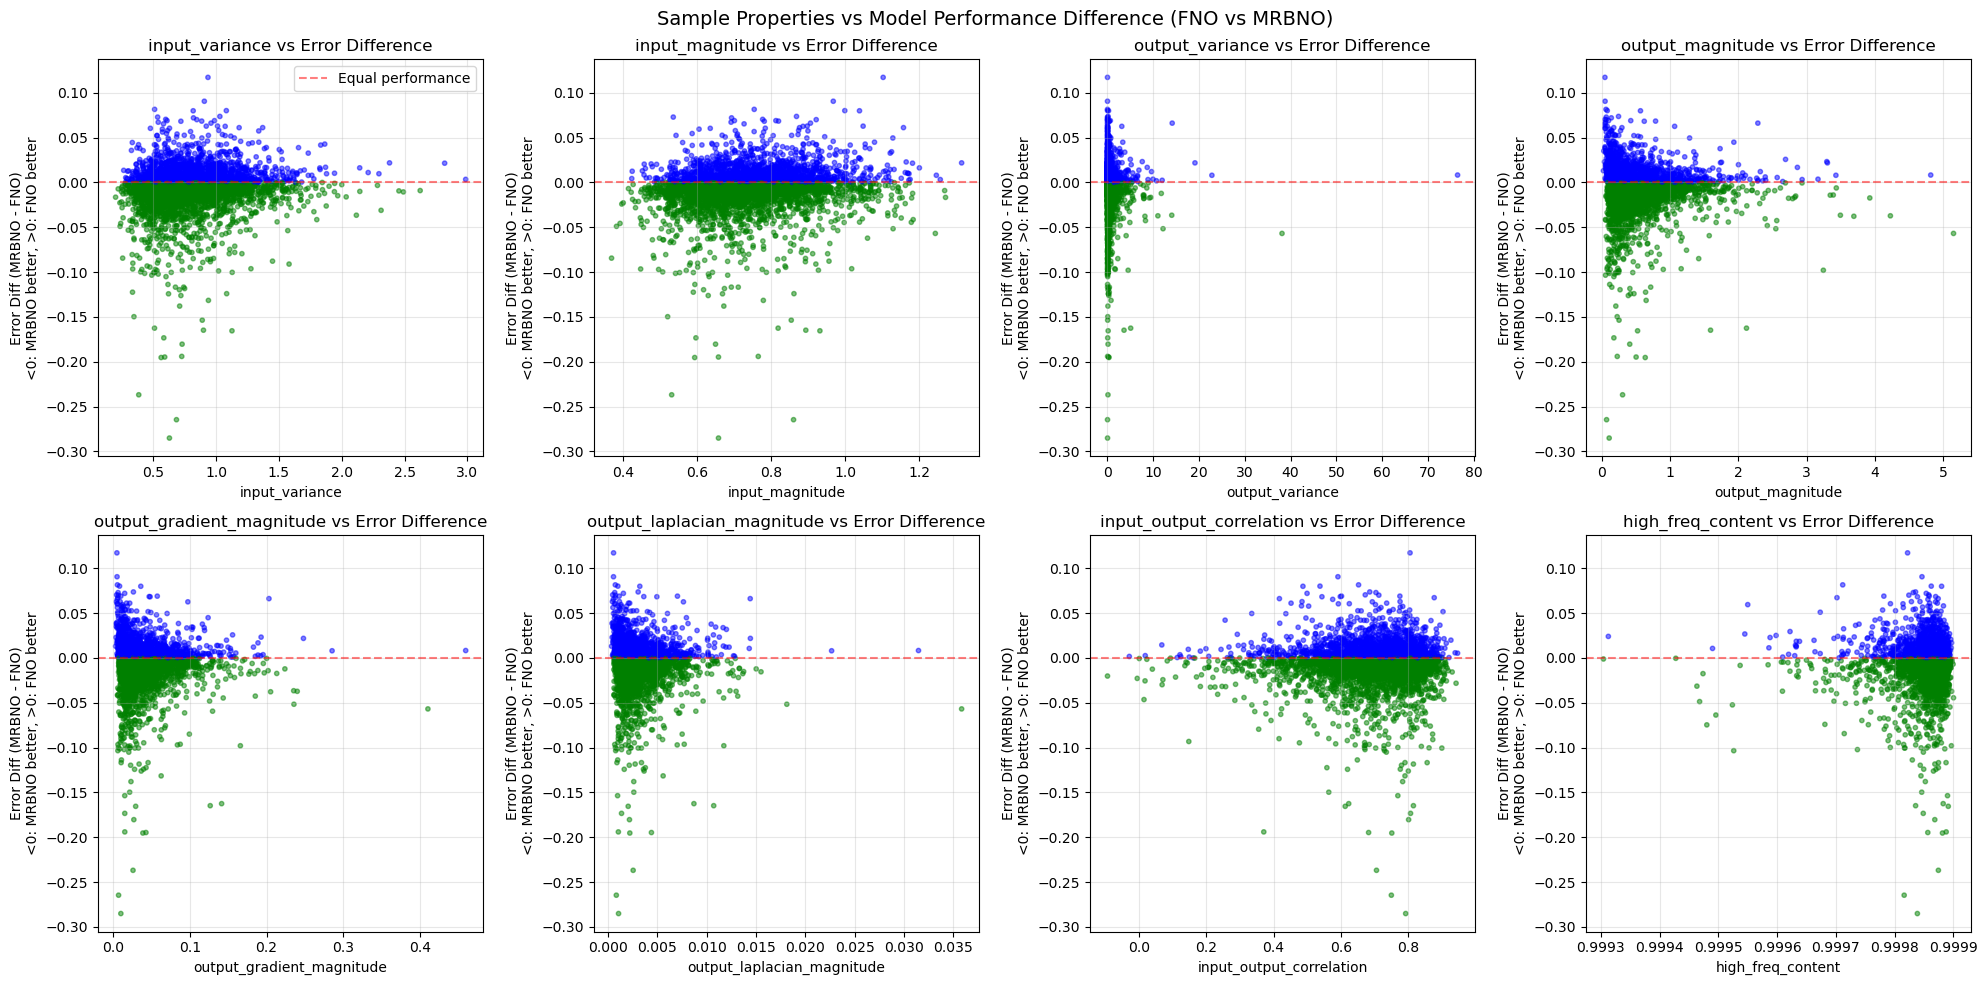

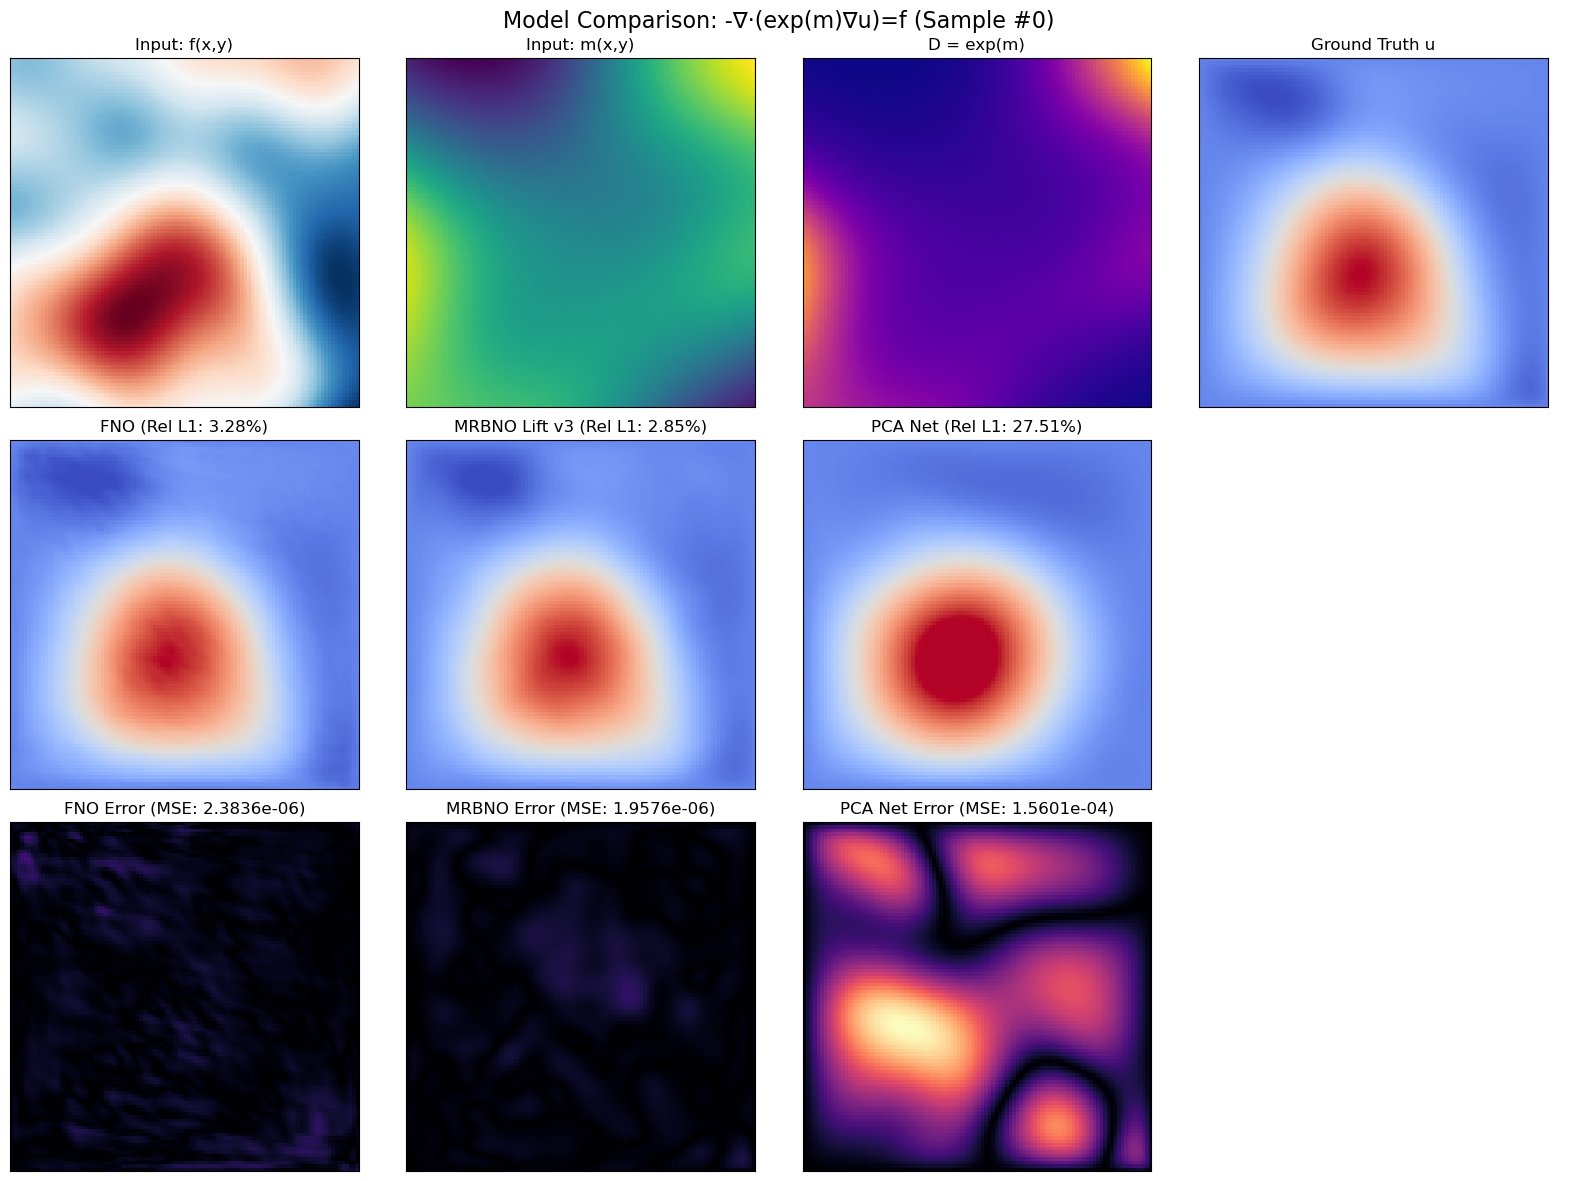

In [16]:
## 7a. Analyze Which Samples FNO vs MRBNO Perform Better On

# Compare per-sample errors between FNO and MRBNO
fno_errors = fno_stats['per_sample_errors']
mrbno_errors = mrbno_stats['per_sample_errors']

# Find samples where each model performs better
fno_better = fno_errors < mrbno_errors
mrbno_better = mrbno_errors < fno_errors
tie = np.abs(fno_errors - mrbno_errors) < 1e-6  # Very close errors

print("="*70)
print("MODEL PERFORMANCE COMPARISON (FNO vs MRBNO Lift Simple)")
print("="*70)
print(f"\nFNO performs better: {np.sum(fno_better)} samples ({np.sum(fno_better)/len(fno_better)*100:.1f}%)")
print(f"MRBNO performs better: {np.sum(mrbno_better)} samples ({np.sum(mrbno_better)/len(mrbno_better)*100:.1f}%)")
print(f"Similar performance: {np.sum(tie)} samples")

# Compute properties for all validation samples
def compute_sample_properties(X_val_t, Y_val_t, device):
    """Compute various properties of samples that might explain model performance differences."""
    properties = {
        'input_variance': [],
        'input_magnitude': [],
        'output_variance': [],
        'output_magnitude': [],
        'output_gradient_magnitude': [],  # Spatial gradient ||∇u||
        'output_laplacian_magnitude': [],  # ||Δu||
        'input_output_correlation': [],
        'high_freq_content': [],  # Energy in high frequencies
    }
    
    # Convert to numpy for processing
    X_val_np = X_val_t.cpu().numpy()
    Y_val_np = Y_val_t.cpu().numpy()
    
    for i in range(len(X_val_np)):
        x_sample = X_val_np[i]  # (C, H, W) for multi-channel or (H, W) for single channel
        y_sample = Y_val_np[i]  # (1, H, W) or (H, W)
        
        # Handle different shapes
        if x_sample.ndim == 3:
            # Multi-channel input (e.g., 2 channels: f and m)
            # Compute properties per channel and average
            x_channels = [x_sample[c] for c in range(x_sample.shape[0])]
            x_combined = x_sample  # Keep full for some properties
        else:
            x_channels = [x_sample]
            x_combined = x_sample[np.newaxis, :, :] if x_sample.ndim == 2 else x_sample
        
        if y_sample.ndim == 3:
            y_sample = y_sample[0]
        elif y_sample.ndim == 2:
            pass  # Already 2D
        
        # Input properties (average across channels)
        input_vars = [np.var(x_ch) for x_ch in x_channels]
        input_mags = [np.abs(x_ch).mean() for x_ch in x_channels]
        properties['input_variance'].append(np.mean(input_vars))
        properties['input_magnitude'].append(np.mean(input_mags))
        
        # Output properties
        properties['output_variance'].append(np.var(y_sample))
        properties['output_magnitude'].append(np.abs(y_sample).mean())
        
        # Spatial gradient (finite difference)
        grad_y = np.gradient(y_sample)
        grad_magnitude = np.sqrt(grad_y[0]**2 + grad_y[1]**2)
        properties['output_gradient_magnitude'].append(np.mean(grad_magnitude))
        
        # Laplacian (second derivatives)
        laplacian = np.gradient(np.gradient(y_sample)[0])[0] + np.gradient(np.gradient(y_sample)[1])[1]
        properties['output_laplacian_magnitude'].append(np.abs(laplacian).mean())
        
        # Input-output correlation (for multi-channel, use channel with highest correlation)
        if x_sample.ndim == 3:
            max_corr = max([np.corrcoef(x_ch.flatten(), y_sample.flatten())[0,1] if x_ch.shape == y_sample.shape else 0.0 
                           for x_ch in x_channels], default=0.0)
            properties['input_output_correlation'].append(max_corr)
        else:
            if x_sample.shape == y_sample.shape:
                properties['input_output_correlation'].append(np.corrcoef(x_sample.flatten(), y_sample.flatten())[0,1])
            else:
                properties['input_output_correlation'].append(0.0)
        
        # High-frequency content (via FFT)
        fft_y = np.fft.fft2(y_sample)
        fft_magnitude = np.abs(fft_y)
        # High frequencies are outer region of FFT (upper half in frequency domain)
        H, W = y_sample.shape
        center_h, center_w = H // 2, W // 2
        mask = np.ones((H, W), dtype=bool)
        # Low frequencies are near center
        mask[center_h-H//4:center_h+H//4, center_w-W//4:center_w+W//4] = False
        high_freq_energy = fft_magnitude[mask].sum()
        total_energy = fft_magnitude.sum()
        properties['high_freq_content'].append(high_freq_energy / (total_energy + 1e-10))
    
    # Convert to numpy arrays
    for key in properties:
        properties[key] = np.array(properties[key])
    
    return properties

print("\nComputing sample properties...")
sample_properties = compute_sample_properties(X_val_t, Y_val_t, device)

# Compare properties between samples where FNO wins vs MRBNO wins
print("\n" + "="*70)
print("PROPERTY ANALYSIS: FNO Better vs MRBNO Better Samples")
print("="*70)

property_names = [
    'input_variance', 'input_magnitude', 'output_variance', 'output_magnitude',
    'output_gradient_magnitude', 'output_laplacian_magnitude',
    'input_output_correlation', 'high_freq_content'
]

print(f"\n{'Property':<30} {'FNO Better (mean±std)':<30} {'MRBNO Better (mean±std)':<30} {'Difference':<20}")
print("-" * 110)

for prop_name in property_names:
    fno_better_vals = sample_properties[prop_name][fno_better]
    mrbno_better_vals = sample_properties[prop_name][mrbno_better]
    
    fno_mean = np.mean(fno_better_vals) if len(fno_better_vals) > 0 else 0
    fno_std = np.std(fno_better_vals) if len(fno_better_vals) > 0 else 0
    mrbno_mean = np.mean(mrbno_better_vals) if len(mrbno_better_vals) > 0 else 0
    mrbno_std = np.std(mrbno_better_vals) if len(mrbno_better_vals) > 0 else 0
    
    diff = mrbno_mean - fno_mean
    diff_pct = (diff / (fno_mean + 1e-10)) * 100 if fno_mean > 0 else 0
    
    fno_str = f"{fno_mean:.4e} ± {fno_std:.4e}" if len(fno_better_vals) > 0 else "N/A"
    mrbno_str = f"{mrbno_mean:.4e} ± {mrbno_std:.4e}" if len(mrbno_better_vals) > 0 else "N/A"
    diff_str = f"{diff:.4e} ({diff_pct:+.1f}%)"
    
    print(f"{prop_name:<30} {fno_str:<30} {mrbno_str:<30} {diff_str:<20}")

# Identify key distinguishing factors
print("\n" + "="*70)
print("KEY INSIGHTS")
print("="*70)

# Find properties with largest relative differences
relative_diffs = {}
for prop_name in property_names:
    fno_vals = sample_properties[prop_name][fno_better]
    mrbno_vals = sample_properties[prop_name][mrbno_better]
    if len(fno_vals) > 0 and len(mrbno_vals) > 0:
        fno_mean = np.mean(fno_vals)
        mrbno_mean = np.mean(mrbno_vals)
        if fno_mean > 0:
            rel_diff = abs((mrbno_mean - fno_mean) / fno_mean)
            relative_diffs[prop_name] = rel_diff

# Sort by relative difference
sorted_props = sorted(relative_diffs.items(), key=lambda x: x[1], reverse=True)

print("\nProperties that most distinguish FNO-better vs MRBNO-better samples:")
for i, (prop_name, rel_diff) in enumerate(sorted_props[:5], 1):
    fno_vals = sample_properties[prop_name][fno_better]
    mrbno_vals = sample_properties[prop_name][mrbno_better]
    fno_mean = np.mean(fno_vals)
    mrbno_mean = np.mean(mrbno_vals)
    print(f"{i}. {prop_name}:")
    print(f"   FNO-better samples: {fno_mean:.4e}")
    print(f"   MRBNO-better samples: {mrbno_mean:.4e}")
    print(f"   Relative difference: {rel_diff*100:.1f}%")
    
    # Interpretation
    if mrbno_mean > fno_mean:
        print(f"   → MRBNO performs better on samples with HIGHER {prop_name}")
    else:
        print(f"   → MRBNO performs better on samples with LOWER {prop_name}")

# Visualization: Scatter plot of error difference vs properties
print("\n" + "="*70)
print("VISUALIZING ERROR DIFFERENCE vs SAMPLE PROPERTIES")
print("="*70)

error_diff = mrbno_errors - fno_errors  # Positive means MRBNO worse, negative means MRBNO better

# Create scatter plots
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, prop_name in enumerate(property_names[:8]):
    ax = axes[i]
    prop_vals = sample_properties[prop_name]
    
    # Color by which model performs better (green = MRBNO better, blue = FNO better)
    colors = ['green' if e < 0 else 'blue' for e in error_diff]
    ax.scatter(prop_vals, error_diff, c=colors, alpha=0.5, s=10)
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Equal performance')
    ax.set_xlabel(prop_name)
    ax.set_ylabel('Error Diff (MRBNO - FNO)\n<0: MRBNO better, >0: FNO better')
    ax.set_title(f'{prop_name} vs Error Difference')
    ax.grid(True, alpha=0.3)
    if i == 0:
        ax.legend()

plt.suptitle('Sample Properties vs Model Performance Difference (FNO vs MRBNO)', fontsize=14)
plt.tight_layout()
plt.show()

## 7. Visualize Predictions

# Pick validation sample and get predictions with relative L1 errors
idx = 0
x_sample = X_val_t[idx:idx+1].to(device)
y_true = Y_val_t[idx].cpu().numpy()[0]

fno_model.eval()
mrbno_model.eval()
pcanet_model.eval()

with torch.no_grad():
    fno_pred = fno_model(x_sample).cpu().numpy()[0, 0]
    mrbno_pred = mrbno_model(x_sample).cpu().numpy()[0, 0]
    pcanet_pred = pcanet_model(x_sample).cpu().numpy()[0, 0]

# Denormalize
f_sample = (x_sample[0, 0].cpu().numpy() * x_std + x_mean)
m_sample = (x_sample[0, 1].cpu().numpy() * x_std + x_mean)
y_true_denorm = y_true * y_std + y_mean
fno_pred_denorm = fno_pred * y_std + y_mean
mrbno_pred_denorm = mrbno_pred * y_std + y_mean
pcanet_pred_denorm = pcanet_pred * y_std + y_mean

# Compute errors
fno_err = np.abs(fno_pred_denorm - y_true_denorm)
mrbno_err = np.abs(mrbno_pred_denorm - y_true_denorm)
pcanet_err = np.abs(pcanet_pred_denorm - y_true_denorm)

# Compute relative L1 errors for this sample
fno_rel_l1_sample = np.sum(fno_err) / np.sum(np.abs(y_true_denorm))
mrbno_rel_l1_sample = np.sum(mrbno_err) / np.sum(np.abs(y_true_denorm))
pcanet_rel_l1_sample = np.sum(pcanet_err) / np.sum(np.abs(y_true_denorm))

err_max = max(fno_err.max(), mrbno_err.max(), pcanet_err.max())

# Plot
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

# Row 1: Inputs
axes[0, 0].imshow(f_sample, origin='lower', cmap='RdBu_r')
axes[0, 0].set_title('Input: f(x,y)')
axes[0, 1].imshow(m_sample, origin='lower', cmap='viridis')
axes[0, 1].set_title('Input: m(x,y)')
axes[0, 2].imshow(np.exp(m_sample), origin='lower', cmap='plasma')
axes[0, 2].set_title('D = exp(m)')
axes[0, 3].imshow(y_true_denorm, origin='lower', cmap='coolwarm')
axes[0, 3].set_title('Ground Truth u')

# Row 2: Predictions
vmin, vmax = y_true_denorm.min(), y_true_denorm.max()
axes[1, 0].imshow(fno_pred_denorm, origin='lower', cmap='coolwarm', vmin=vmin, vmax=vmax)
axes[1, 0].set_title(f'FNO (Rel L1: {fno_rel_l1_sample*100:.2f}%)')
axes[1, 1].imshow(mrbno_pred_denorm, origin='lower', cmap='coolwarm', vmin=vmin, vmax=vmax)
axes[1, 1].set_title(f'MRBNO Lift Simple (Rel L1: {mrbno_rel_l1_sample*100:.2f}%)')
axes[1, 2].imshow(pcanet_pred_denorm, origin='lower', cmap='coolwarm', vmin=vmin, vmax=vmax)
axes[1, 2].set_title(f'PCA Net (Rel L1: {pcanet_rel_l1_sample*100:.2f}%)')
axes[1, 3].axis('off')

# Row 3: Errors
axes[2, 0].imshow(fno_err, origin='lower', cmap='magma', vmin=0, vmax=err_max)
axes[2, 0].set_title(f'FNO Error (MSE: {np.mean(fno_err**2):.4e})')
axes[2, 1].imshow(mrbno_err, origin='lower', cmap='magma', vmin=0, vmax=err_max)
axes[2, 1].set_title(f'MRBNO Error (MSE: {np.mean(mrbno_err**2):.4e})')
axes[2, 2].imshow(pcanet_err, origin='lower', cmap='magma', vmin=0, vmax=err_max)
axes[2, 2].set_title(f'PCA Net Error (MSE: {np.mean(pcanet_err**2):.4e})')
axes[2, 3].axis('off')

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(f'Model Comparison: -∇·(exp(m)∇u)=f (Sample #{idx})', fontsize=16)
plt.tight_layout()
plt.show()
